# From measured gas uptake to an internal pore population

The complete96-point author Takeda5A nitrogen adsorption branch is inverted using its supplied77-width molecular kernel. This is a **nonspatial pore-population inverse**, distinct from a particle-radius distribution measured by scattering. The output's scale is **kernel-relative**: the response table's absolute pore-volume normalization is unverified, so no cm³/g or true-porosity claim is made.

Six scientific questions guide the active review: observations, physical calibration, full fresh inverse/source agreement, reporting and cross-method interpretation, convergence, and robustness. All fresh results are computed here. Original unmodified source, physically corrected source and fresh local values are separately labeled. No actual true pore distribution is available.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np,scipy
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline,PchipInterpolator
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,calibration_with_origin,width_steps
from src.physics_model import build_kernel,forward
from src.solvers import reconstruct,spline_matrix
from src.main import run
from src.visualization import metrics,normalized_density
raw=load_observations(ROOT/'data/raw_data.npz');p=raw['relative_pressure'];observed=raw['loading'];widths=raw['pore_width']
up=np.load(ROOT/'notebooks/reference_outputs/upstream_analytic_converged.npz',allow_pickle=False)
old=np.load(ROOT/'notebooks/reference_outputs/upstream_unmodified.npz',allow_pickle=False)
hk=np.load(ROOT/'notebooks/reference_outputs/upstream_hk.npz',allow_pickle=False)
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.titlelocation':'left'})
print('Actual kernel NumPy/SciPy',np.__version__,scipy.__version__,'observations',len(p),'calibration',raw['kernel_loading'].shape)


Actual kernel NumPy/SciPy 2.4.6 1.17.1 observations 96 calibration (177, 77)


## 1. Observations and independently supplied forward calibration

The real uptake curve comes from the original author's Triflex/MADIREL specimen record at77.355K. Relative pressures preserve its original conversion with nitrogen saturation pressure1.0132507274270477bar. The kernel is a separately supplied molecular model for carbon slit pores, nominally77K, not estimated using a hidden target. Every one of96 adsorption observations remains; no fitted-quality selection or pressure crop is used. Original177calibration pressure rows and77widths remain unchanged.

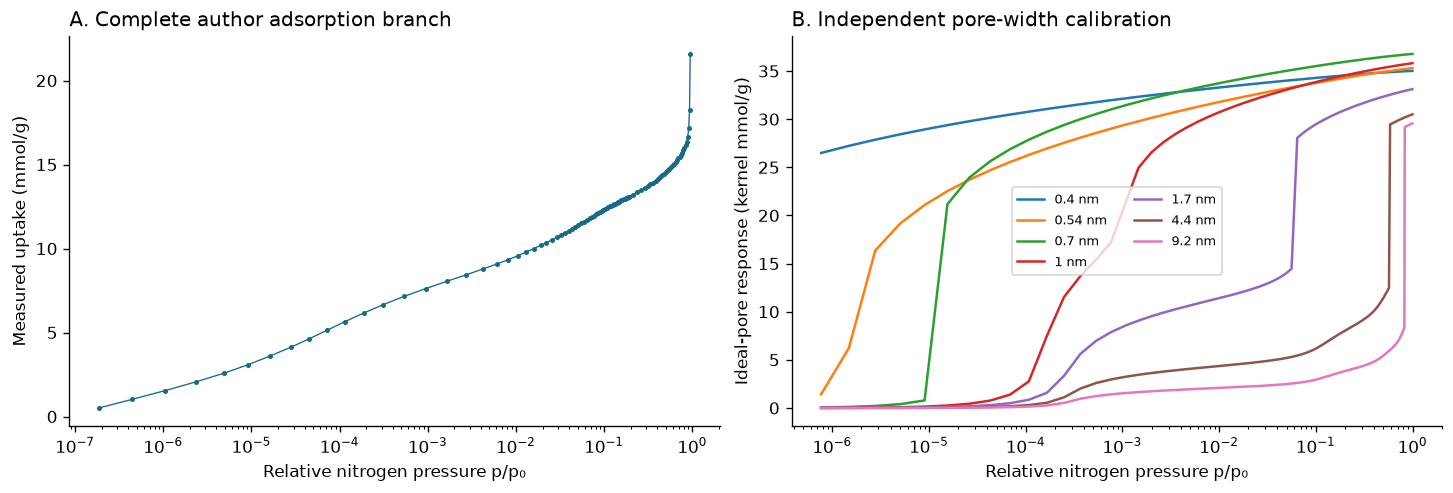

In [2]:
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
ax[0].semilogx(p,observed,'.-',color='#176b87',ms=4,lw=.8);ax[0].set(xlabel='Relative nitrogen pressure p/p₀',ylabel='Measured uptake (mmol/g)',title='A. Complete author adsorption branch')
for j in [0,7,15,30,45,60,76]:ax[1].semilogx(raw['kernel_relative_pressure'],raw['kernel_loading'][:,j],label=f'{widths[j]:g} nm')
ax[1].set(xlabel='Relative nitrogen pressure p/p₀',ylabel='Ideal-pore response (kernel mmol/g)',title='B. Independent pore-width calibration');ax[1].legend(fontsize=8,ncol=2);plt.show()


## 2. A physical calibration defect must be investigated

The original source appends the known zero-pressure/zero-uptake origin and uses unconstrained cubic interpolation. At the first actual measured pressure, that interpolation predicts negative uptake for three widths. Their original final coefficients happen to be nearly zero, but a negative ideal adsorption response is still physically invalid.

The explicit corrected variant uses shape-preserving PCHIP, reproducing every tabulated value and preserving positivity/monotonicity. The molecular calibration itself is **unchanged**. The published kernel-mixture method does not mandate the later implementation's cubic interpolation choice. Original source outputs remain negative evidence and a scientific comparison, not silently overwritten. The second correction tightens an early SLSQP stop so independent starts agree; it changes no objective, constraint or observation.

Original negative native entries 3 PCHIPminimum 0.00019773058583397721 maximum node error 7.105427357601002e-15


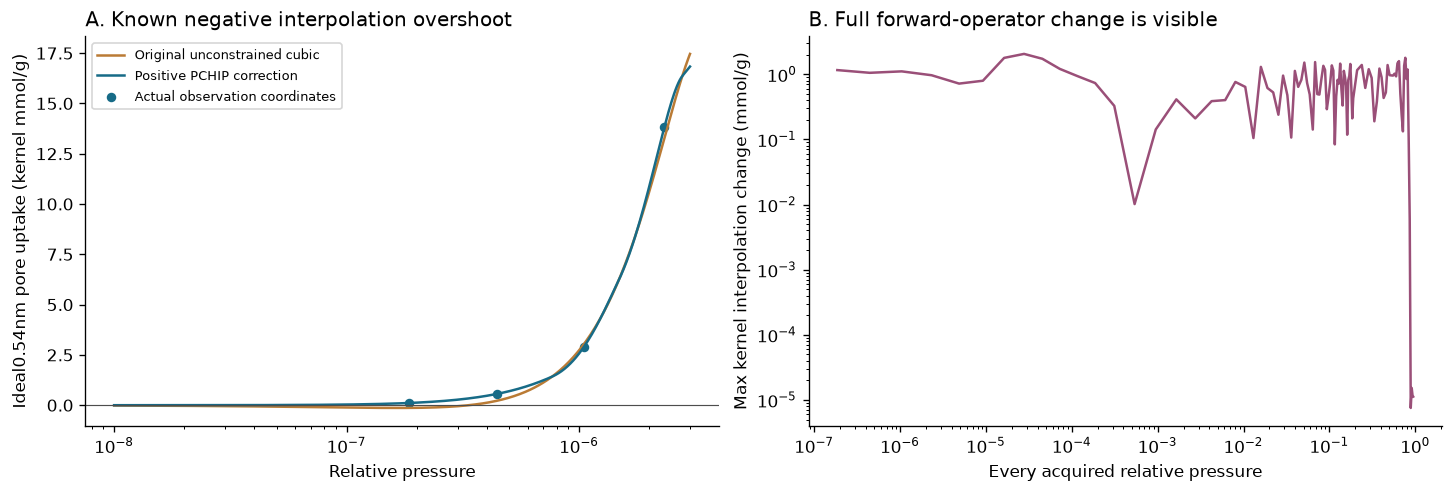

In [3]:
kp,kcal=calibration_with_origin(raw['kernel_relative_pressure'],raw['kernel_loading']);cubic=CubicSpline(kp,kcal,axis=0,extrapolate=False);positive=PchipInterpolator(kp,kcal,axis=0,extrapolate=False)
dense=np.r_[0.,np.geomspace(1e-12,kp[-1],10000)];assert positive(dense).min()>=0
node_error=float(np.max(abs(positive(kp)-kcal)));original_negative=int(np.sum(old['kernel']<0))
print('Original negative native entries',original_negative,'PCHIPminimum',positive(p).min(),'maximum node error',node_error)
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained');zoom=np.geomspace(1e-8,3e-6,400);j=7
ax[0].semilogx(zoom,cubic(zoom)[:,j],color='#ba7b35',label='Original unconstrained cubic');ax[0].semilogx(zoom,positive(zoom)[:,j],color='#176b87',label='Positive PCHIP correction');ax[0].scatter(p[:4],positive(p[:4])[:,j],s=22,color='#176b87',label='Actual observation coordinates');ax[0].axhline(0,color='.3',lw=.7);ax[0].set(xlabel='Relative pressure',ylabel='Ideal0.54nm pore uptake (kernel mmol/g)',title='A. Known negative interpolation overshoot');ax[0].legend(fontsize=8)
relative=np.max(abs(cubic(p)-positive(p)),axis=1);ax[1].loglog(p,relative+1e-18,color='#9a4f78');ax[1].set(xlabel='Every acquired relative pressure',ylabel='Max kernel interpolation change (mmol/g)',title='B. Full forward-operator change is visible');plt.show()


## 3. Fresh full inverse and independent source agreement

The model is $n_i=\sum_j A_j(p_i)x_j+\epsilon_i$, with measured uptake n, known response A, nonnegative dimensionless contribution x and residual epsilon. The objective is the unnormalized sum of all96 squared uptake residuals. The selected source uses nonnegative sequential quadratic programming. Its physically corrected, precision-refined run was frozen independently before local extraction. The following cell actively reconstructs this entire bound case with local modules and saves all three required arrays.
The unchanged physical least-squares objective is optimized after division by the mean squared observed loading, with an analytic gradient and explicit first-order/feasible-dual certificates. This positive constant scaling changes no fitted physical objective. The prior unscaled optimizer could report success without convergence; it is retained as failed evidence below.


Freshseconds 0.05929070001002401 actualiterations 88 objective 20.970090134873047
Weights {'ncc': 1.0, 'nrmse': 1.6477500392364447e-13} density {'ncc': 0.9999999999999999, 'nrmse': 1.3944069191930416e-13}
Full observationrelativeL2 0.03809624630655208


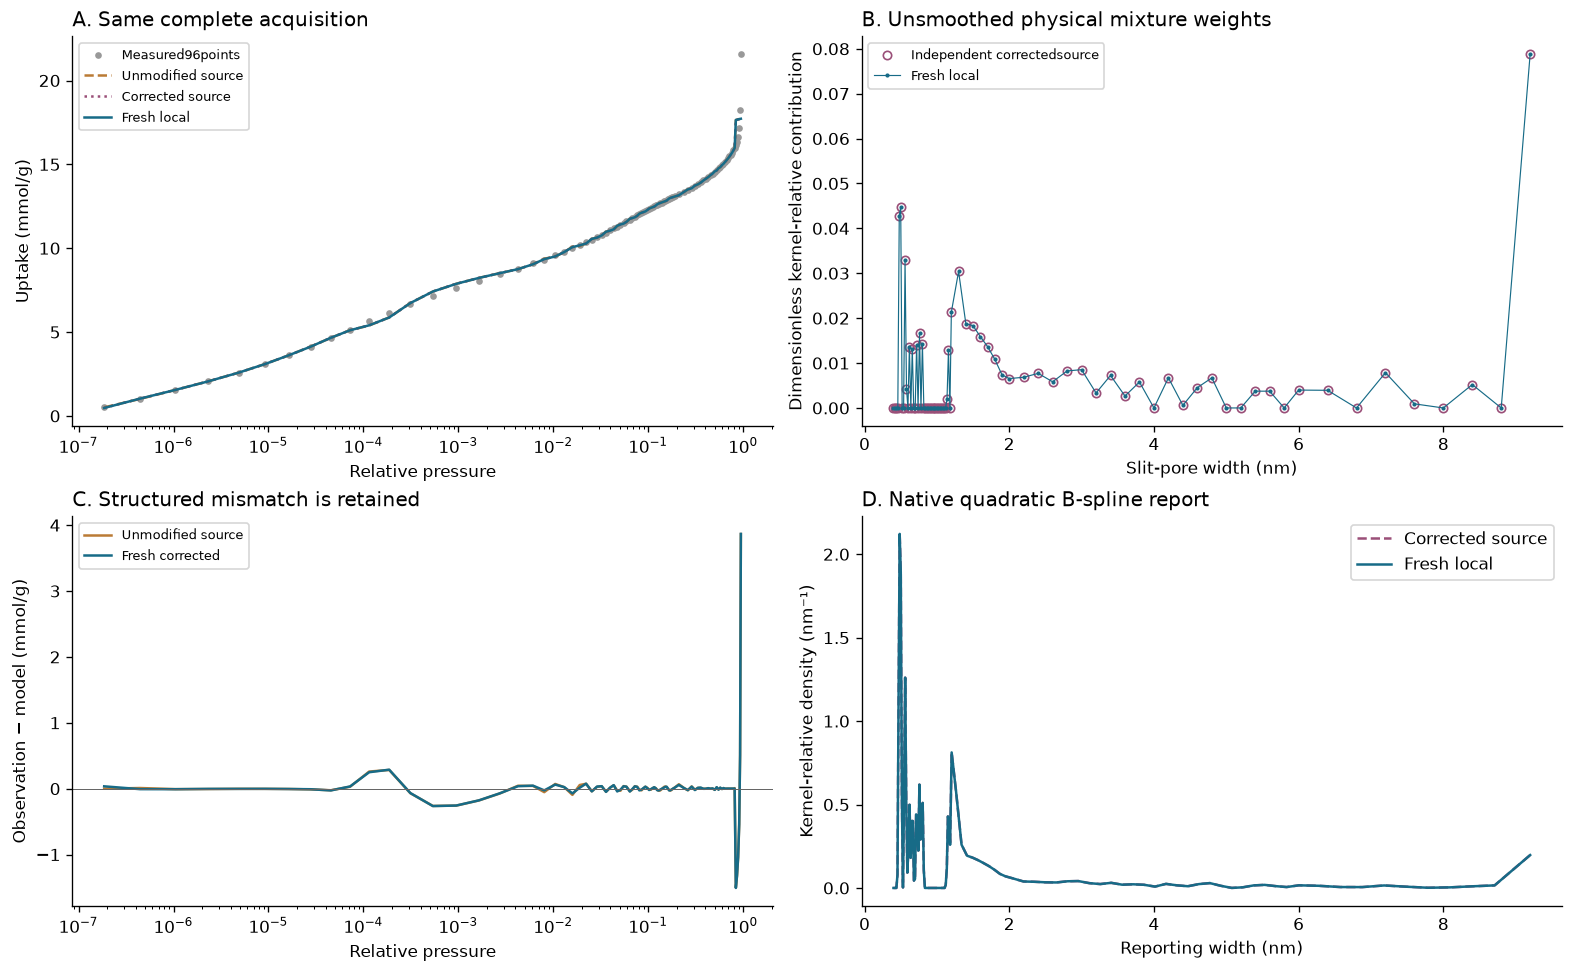

In [4]:
fresh=run();np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_standard.npz',**{k:fresh[k][None] for k in ['reconstruction','bin_weights','cumulative_weights']})
print('Freshseconds',fresh['runtime_seconds'],'actualiterations',fresh['iterations'],'objective',fresh['objective'])
print('Weights',metrics(fresh['bin_weights'],up['bin_weights'][0]),'density',metrics(fresh['reconstruction'],up['reconstruction'][0]))
print('Full observationrelativeL2',np.linalg.norm(fresh['fitted_loading']-observed)/np.linalg.norm(observed))
source_model=forward(up['bin_weights'][0],fresh['kernel']);old_model=old['kernel_loading']
fig,ax=plt.subplots(2,2,figsize=(13,8),layout='constrained')
ax[0,0].semilogx(p,observed,'.',color='.6',label='Measured96points');ax[0,0].semilogx(p,old_model,'--',color='#ba7b35',label='Unmodified source');ax[0,0].semilogx(p,source_model,':',color='#9a4f78',label='Corrected source');ax[0,0].semilogx(p,fresh['fitted_loading'],color='#176b87',label='Fresh local');ax[0,0].set(xlabel='Relative pressure',ylabel='Uptake (mmol/g)',title='A. Same complete acquisition');ax[0,0].legend(fontsize=8)
ax[0,1].plot(widths,up['bin_weights'][0],'o',mfc='none',color='#9a4f78',ms=5,label='Independent correctedsource');ax[0,1].plot(widths,fresh['bin_weights'],'.-',color='#176b87',ms=3,lw=.7,label='Fresh local');ax[0,1].set(xlabel='Slit-pore width (nm)',ylabel='Dimensionless kernel-relative contribution',title='B. Unsmoothed physical mixture weights');ax[0,1].legend(fontsize=8)
ax[1,0].semilogx(p,observed-old_model,color='#ba7b35',label='Unmodified source');ax[1,0].semilogx(p,observed-fresh['fitted_loading'],color='#176b87',label='Fresh corrected');ax[1,0].axhline(0,color='.4',lw=.6);ax[1,0].set(xlabel='Relative pressure',ylabel='Observation − model (mmol/g)',title='C. Structured mismatch is retained');ax[1,0].legend(fontsize=8)
ax[1,1].plot(fresh['width_axis'],up['reconstruction'][0],'--',color='#9a4f78',label='Corrected source');ax[1,1].plot(fresh['width_axis'],fresh['reconstruction'],color='#176b87',label='Fresh local');ax[1,1].set(xlabel='Reporting width (nm)',ylabel='Kernel-relative density (nm⁻¹)',title='D. Native quadratic B-spline report');ax[1,1].legend();plt.show()


## 4. Reporting smoothing and the published cross-method question

Unsmoothed77bin weights predict the measured isotherm. The source's quadratic control-curve spline produces100reporting samples and a cumulative quantity; it is not a new physical forward fit and does not exactly preserve the unsmoothed bin sum. We retain those distinctions and compare actualdegree0,2,5reporting operators.

The original publication discusses HK versus molecular-kernel pore profiles and the limitations of applying a kernel to an unsuitable geometry. Its historical example is UiO66, whereas this bound case is the author's later native Takeda5A carbon example. The same Takeda specimen's original **upstreamHK** fit was independently executed and frozen for the comparison below. It is not a newly implemented/freshHK solver or reproduction of the original UiO66figure. Because absolute normalization of this DFTtable is unverified, compare **unit-area width-profile shapes only**, not absolute pore volumes or accuracy against a true structure.

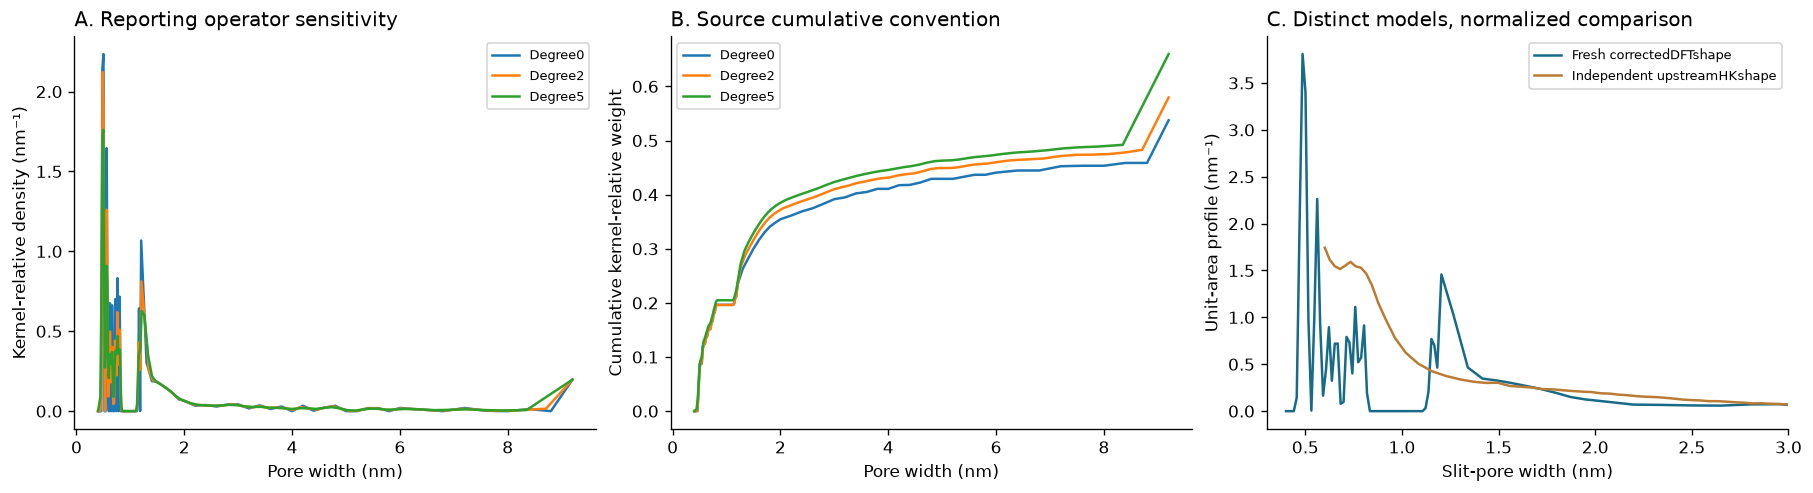

Rawweight sum 0.5375016787561269 reportedcumulative endpoint 0.5796560835608109 not assumed identical


In [5]:
reporting=[]
for degree in [0,2,5]:
    S=spline_matrix(len(widths),degree);axis=S@widths;density=S@fresh['unsmoothed_density'];cumulative=np.cumsum(density*width_steps(axis));reporting.append((degree,axis,density,cumulative))
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
for degree,axis,density,cumulative in reporting:
    ax[0].plot(axis,density,label=f'Degree{degree}');ax[1].plot(axis,cumulative,label=f'Degree{degree}')
ax[0].set(xlabel='Pore width (nm)',ylabel='Kernel-relative density (nm⁻¹)',title='A. Reporting operator sensitivity');ax[0].legend(fontsize=8)
ax[1].set(xlabel='Pore width (nm)',ylabel='Cumulative kernel-relative weight',title='B. Source cumulative convention');ax[1].legend(fontsize=8)
ax[2].plot(fresh['width_axis'],normalized_density(fresh['width_axis'],fresh['reconstruction']),color='#176b87',label='Fresh correctedDFTshape')
ax[2].plot(hk['pore_widths'],normalized_density(hk['pore_widths'],hk['pore_distribution']),color='#ba7b35',label='Independent upstreamHKshape')
ax[2].set(xlabel='Slit-pore width (nm)',ylabel='Unit-area profile (nm⁻¹)',title='C. Distinct models, normalized comparison',xlim=(.3,3));ax[2].legend(fontsize=8);plt.show()
print('Rawweight sum',fresh['bin_weights'].sum(),'reportedcumulative endpoint',fresh['cumulative_weights'][-1],'not assumed identical')


## 5. Better convergence must not fail through a hidden trajectory

The source default stopped early enough to change weak weights despite a small total-loss change. The chosen refined source was qualified using independent zero,uniform and exactNNLS starting points before local extraction; its table and objective were not altered to ease the inverse. Below, three fully fresh public-data starts test the local estimator again. Their differences must be read on the stated physical/kernel-relative scale, not hidden by independently normalizing each result.

Zero objective 20.970090134873047 seconds 0.05757070000981912 weight comparison {'ncc': 1.0, 'nrmse': 0.0} certificate {'projected_kkt': 7.529220302782136e-14, 'relative_primal_dual_gap': 5.958609150134193e-09}
Uniform0.005 objective 20.970090134873026 seconds 0.05903870001202449 weight comparison {'ncc': 0.9999999999999967, 'nrmse': 1.5182664726213365e-08} certificate {'projected_kkt': 8.623310399080708e-15, 'relative_primal_dual_gap': 9.436951291889237e-10}
Uniform0.01 objective 20.97009013487309 seconds 0.05788459995528683 weight comparison {'ncc': 0.9999999999975469, 'nrmse': 4.0159988668096214e-07} certificate {'projected_kkt': 3.3741618440247256e-13, 'relative_primal_dual_gap': 3.784527667580462e-08}


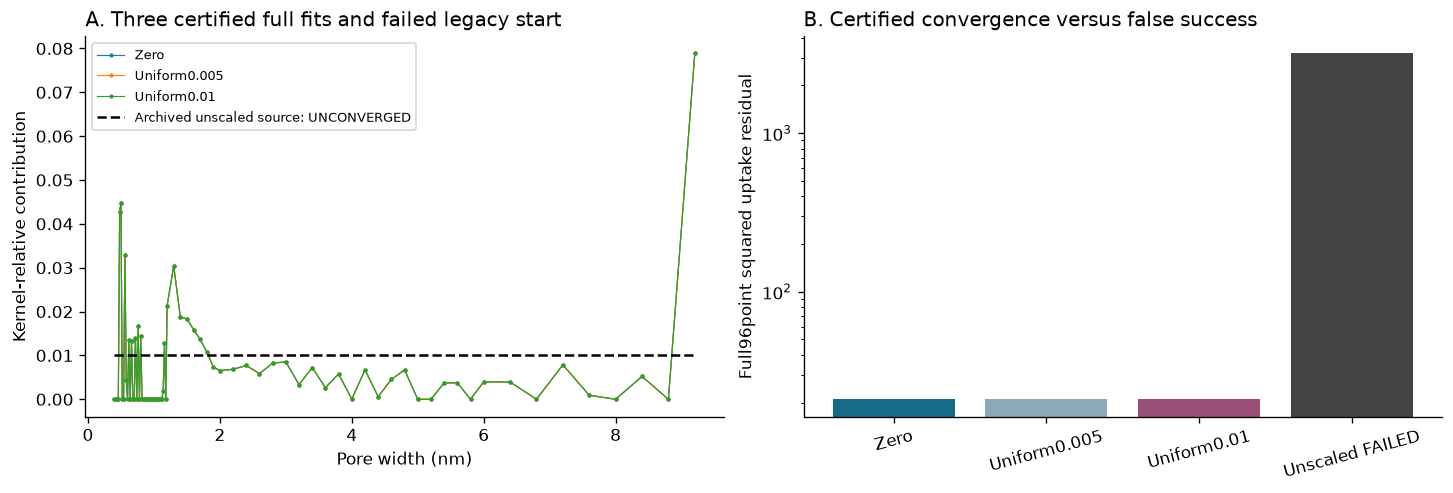

Archived unscaled analytic-source success flag was true, but projectedKKT 0.004002838759089763 and objective 3182.8716367546763 prove it did not converge.


In [6]:
starts=[]
for name,initial in [('Zero',np.zeros(77)),('Uniform0.005',np.full(77,.005)),('Uniform0.01',np.full(77,.01))]:
    start=time.perf_counter();fit=reconstruct(raw,initial=initial);seconds=time.perf_counter()-start;starts.append((name,fit,seconds))
    print(name,'objective',fit['objective'],'seconds',seconds,'weight comparison',metrics(fit['bin_weights'],fresh['bin_weights']),'certificate',fit['convergence_certificate'])
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for name,fit,seconds in starts:ax[0].plot(widths,fit['bin_weights'],'.-',ms=3,lw=.7,label=name)
failed=np.load(ROOT/'notebooks/reference_outputs/upstream_failed_uniform.npz');ax[0].plot(widths,failed['coefficients'],'--',color='black',label='Archived unscaled source: UNCONVERGED');ax[0].set(xlabel='Pore width (nm)',ylabel='Kernel-relative contribution',title='A. Three certified full fits and failed legacy start');ax[0].legend(fontsize=8)
ax[1].bar([name for name,_,_ in starts]+['Unscaled FAILED'],[fit['objective'] for _,fit,_ in starts]+[float(failed['objective'])],color=['#176b87','#8ba9b7','#9a4f78','#444444']);ax[1].set(yscale='log',ylabel='Full96point squared uptake residual',title='B. Certified convergence versus false success');ax[1].tick_params(axis='x',rotation=15);plt.show();print('Archived unscaled analytic-source success flag was true, but projectedKKT',float(failed['projected_kkt']),'and objective',float(failed['objective']),'prove it did not converge.')


## 6. Computed robustness and independent evaluation

Measurement noise variance is not supplied. The following nine refits add illustrative independent Gaussian perturbations of1%,3% and5% of the **public observed uptake**, three runs each. These are stated stress scenarios, not a claimed acquisitionnoise calibration, hidden clean curve, or true-pore accuracy measurement. All96 observations and all77widths remain in every refit. Run-to-run SD from three trials is sensitivity, not a calibrated confidence interval.

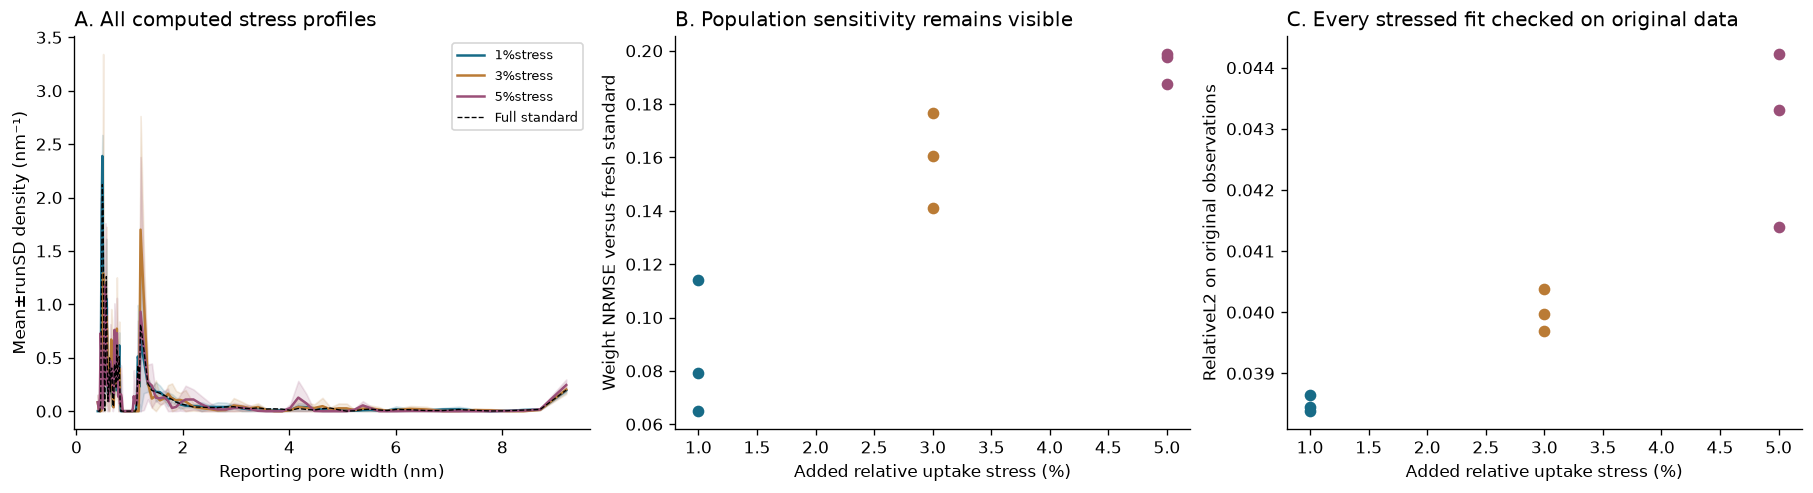

[
  {
    "stress_fraction": 0.01,
    "repeat": 0,
    "seconds": 0.05519300000742078,
    "objective": 21.023710520037714
  },
  {
    "stress_fraction": 0.01,
    "repeat": 1,
    "seconds": 0.05557809997117147,
    "objective": 22.910880541410254
  },
  {
    "stress_fraction": 0.01,
    "repeat": 2,
    "seconds": 0.05154829996172339,
    "objective": 19.88984044524502
  },
  {
    "stress_fraction": 0.03,
    "repeat": 0,
    "seconds": 0.06597439997131005,
    "objective": 25.97662660973166
  },
  {
    "stress_fraction": 0.03,
    "repeat": 1,
    "seconds": 0.05242399999406189,
    "objective": 27.632077988373805
  },
  {
    "stress_fraction": 0.03,
    "repeat": 2,
    "seconds": 0.049003299965988845,
    "objective": 40.19215903542145
  },
  {
    "stress_fraction": 0.05,
    "repeat": 0,
    "seconds": 0.03364849998615682,
    "objective": 44.78565403711413
  },
  {
    "stress_fraction": 0.05,
    "repeat": 1,
    "seconds": 0.04759230004856363,
    "objective": 69.971562

In [7]:
rng=np.random.default_rng(20261026);runs=[]
for fraction in [.01,.03,.05]:
    for repeat in range(3):
        changed={k:v.copy() for k,v in raw.items()};changed['loading']=observed+rng.normal(size=96)*fraction*observed
        start=time.perf_counter();fit=reconstruct(changed);runs.append((fraction,repeat,fit,time.perf_counter()-start))
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
for fraction,color in zip([.01,.03,.05],['#176b87','#ba7b35','#9a4f78']):
    group=[f for level,_,f,_ in runs if level==fraction];densities=np.array([f['reconstruction'] for f in group]);mean=densities.mean(0);sd=densities.std(0,ddof=1)
    ax[0].plot(fresh['width_axis'],mean,color=color,label=f'{fraction:.0%}stress');ax[0].fill_between(fresh['width_axis'],np.maximum(mean-sd,0),mean+sd,color=color,alpha=.15)
    ax[1].scatter(np.full(3,fraction*100),[metrics(f['bin_weights'],fresh['bin_weights'])['nrmse'] for f in group],color=color)
    ax[2].scatter(np.full(3,fraction*100),[np.linalg.norm(f['fitted_loading']-observed)/np.linalg.norm(observed) for f in group],color=color)
ax[0].plot(fresh['width_axis'],fresh['reconstruction'],'k--',lw=.8,label='Full standard');ax[0].set(xlabel='Reporting pore width (nm)',ylabel='Mean±runSD density (nm⁻¹)',title='A. All computed stress profiles');ax[0].legend(fontsize=8)
ax[1].set(xlabel='Added relative uptake stress (%)',ylabel='Weight NRMSE versus fresh standard',title='B. Population sensitivity remains visible')
ax[2].set(xlabel='Added relative uptake stress (%)',ylabel='RelativeL2 on original observations',title='C. Every stressed fit checked on original data');plt.show()
print(json.dumps([dict(stress_fraction=level,repeat=repeat,seconds=seconds,objective=fit['objective']) for level,repeat,fit,seconds in runs],indent=2))
from importlib.util import spec_from_file_location,module_from_spec
spec=spec_from_file_location('pore_notebook_judge',ROOT/'evaluation/judge.py');judge=module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(ROOT/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert code==0


The active corrected inverse reproduces an independently executed physically positive kernel interpolation and converged nonnegative mixture fit, retaining the original calibration and all96real observations. The unmodified-source interpolation defect and earlystop evidence remain visible. Reporting smoothing, upstreamHKcontrast, independent starts and noise stresses expose model and numerical sensitivity. Reference agreement and a3.8%uptake fit do not establish a unique real pore geometry or an absolute pore volume.